In [12]:
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 2. Cross-Platform Hardware Acceleration (Mac MPS, Windows/Linux CUDA, or CPU)
device = torch.device(
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
print(f"Using device: {device}")

Using device: mps


In [13]:
DATA_DIR = Path("data")
IMG_SIZE = 224
BATCH_SIZE = 8  # Optimized for 51 total images

valid_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

gauge_dir = DATA_DIR / "gauge"
# Automatically support either 'not_gauge' or 'not-gauge'
not_gauge_dir = DATA_DIR / "not_gauge" if (DATA_DIR / "not_gauge").exists() else DATA_DIR / "not-gauge"

gauge_files = [p for p in gauge_dir.glob("*") if p.suffix.lower() in valid_exts]
not_gauge_files = [p for p in not_gauge_dir.glob("*") if p.suffix.lower() in valid_exts]

all_files = gauge_files + not_gauge_files
all_labels = [1] * len(gauge_files) + [0] * len(not_gauge_files)

print(f"Found {len(gauge_files)} Gauge images (YES) and {len(not_gauge_files)} Non-Gauge images (NO).")

# Stratified 70% Train (~35 imgs), 15% Val (~8 imgs), 15% Test (~8 imgs)
X_train, X_temp, y_train, y_temp = train_test_split(
    all_files, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
print(f"Split -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

class GaugeDataset(Dataset):
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img = Image.open(self.file_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.float32)

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_loader = DataLoader(GaugeDataset(X_train, y_train, train_tfms), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(GaugeDataset(X_val, y_val, eval_tfms), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(GaugeDataset(X_test, y_test, eval_tfms), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

Found 24 Gauge images (YES) and 26 Non-Gauge images (NO).
Split -> Train: 35 | Val: 7 | Test: 8


In [14]:
EPOCHS = 12
MODEL_PATH = Path("models/best_gauge_model.pt")
MODEL_PATH.parent.mkdir(exist_ok=True)

model = timm.create_model("efficientnet_b0", pretrained=True, num_classes=1, drop_rate=0.3)

# 1. Freeze base backbone so we don't overfit on 35 training images
for param in model.parameters():
    param.requires_grad = False

# 2. Unfreeze the top feature block and final classifier head
for name, param in model.named_parameters():
    if "blocks.6" in name or "conv_head" in name or "bn2" in name or "classifier" in name:
        param.requires_grad = True

model = model.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=5e-4, weight_decay=1e-2)

def evaluate_loader(loader, train_mode=False):
    model.train() if train_mode else model.eval()
    total_loss, probs, targets = 0.0, [], []
    
    with torch.enable_grad() if train_mode else torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.unsqueeze(1).to(device)
            if train_mode:
                optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            if train_mode:
                loss.backward()
                optimizer.step()
                
            total_loss += loss.item() * x.size(0)
            probs.extend(torch.sigmoid(logits).detach().cpu().numpy().flatten())
            targets.extend(y.cpu().numpy().flatten())
            
    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(targets, (np.array(probs) >= 0.5).astype(int))
    return avg_loss, acc, np.array(probs), np.array(targets)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc, _, _ = evaluate_loader(train_loader, train_mode=True)
    va_loss, va_acc, _, _ = evaluate_loader(val_loader, train_mode=False)
    
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)
    
    saved = ""
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(model.state_dict(), MODEL_PATH)
        saved = " [Saved Best]"
        
    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train Loss: {tr_loss:.4f} (Acc: {tr_acc:.1%}) | Val Loss: {va_loss:.4f} (Acc: {va_acc:.1%}){saved}")

Epoch 01/12 | Train Loss: 1.8799 (Acc: 68.6%) | Val Loss: 1.1044 (Acc: 71.4%) [Saved Best]
Epoch 02/12 | Train Loss: 0.2924 (Acc: 91.4%) | Val Loss: 0.9459 (Acc: 71.4%) [Saved Best]
Epoch 03/12 | Train Loss: 0.0004 (Acc: 100.0%) | Val Loss: 0.3106 (Acc: 85.7%) [Saved Best]
Epoch 04/12 | Train Loss: 0.0631 (Acc: 97.1%) | Val Loss: 0.0414 (Acc: 100.0%) [Saved Best]
Epoch 05/12 | Train Loss: 0.0474 (Acc: 97.1%) | Val Loss: 0.8189 (Acc: 85.7%)
Epoch 06/12 | Train Loss: 0.4955 (Acc: 97.1%) | Val Loss: 1.1393 (Acc: 85.7%)
Epoch 07/12 | Train Loss: 0.4029 (Acc: 97.1%) | Val Loss: 1.6648 (Acc: 85.7%)
Epoch 08/12 | Train Loss: 0.2704 (Acc: 94.3%) | Val Loss: 1.4078 (Acc: 85.7%)
Epoch 09/12 | Train Loss: 0.0009 (Acc: 100.0%) | Val Loss: 0.7800 (Acc: 85.7%)
Epoch 10/12 | Train Loss: 0.3175 (Acc: 91.4%) | Val Loss: 1.3208 (Acc: 85.7%)
Epoch 11/12 | Train Loss: 0.2609 (Acc: 94.3%) | Val Loss: 1.4522 (Acc: 85.7%)
Epoch 12/12 | Train Loss: 0.0013 (Acc: 100.0%) | Val Loss: 1.3905 (Acc: 85.7%)


=== TEST SET PERFORMANCE METRICS ===
Accuracy    : 100.00%
Precision   : 100.00% (Positive Predictive Value)
Recall      : 100.00% (Sensitivity / True Positive Rate)
Specificity : 100.00% (True Negative Rate)
F1-Score    : 1.0000
ROC-AUC     : 1.0000

                precision    recall  f1-score   support

NO (not_gauge)       1.00      1.00      1.00         4
   YES (gauge)       1.00      1.00      1.00         4

      accuracy                           1.00         8
     macro avg       1.00      1.00      1.00         8
  weighted avg       1.00      1.00      1.00         8



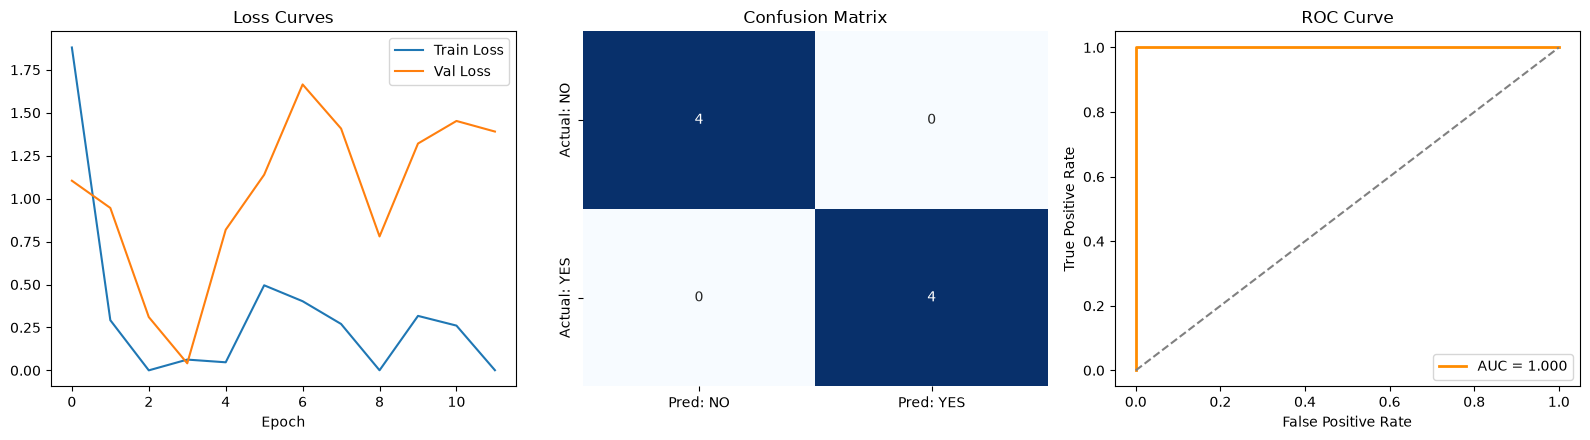

In [15]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
test_loss, test_acc, y_probs, y_true = evaluate_loader(test_loader, train_mode=False)
y_pred = (y_probs >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_probs)

print("=== TEST SET PERFORMANCE METRICS ===")
print(f"Accuracy    : {test_acc:.2%}")
print(f"Precision   : {precision:.2%} (Positive Predictive Value)")
print(f"Recall      : {recall:.2%} (Sensitivity / True Positive Rate)")
print(f"Specificity : {specificity:.2%} (True Negative Rate)")
print(f"F1-Score    : {f1:.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}\n")
print(classification_report(y_true, y_pred, target_names=["NO (not_gauge)", "YES (gauge)"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Loss Curve
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].set_title("Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].legend()

# 2. Confusion Matrix
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Pred: NO", "Pred: YES"], yticklabels=["Actual: NO", "Actual: YES"])
axes[1].set_title("Confusion Matrix")

# 3. ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_probs)
axes[2].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}", color="darkorange", lw=2)
axes[2].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[2].set_title("ROC Curve")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend()

plt.tight_layout()
plt.show()

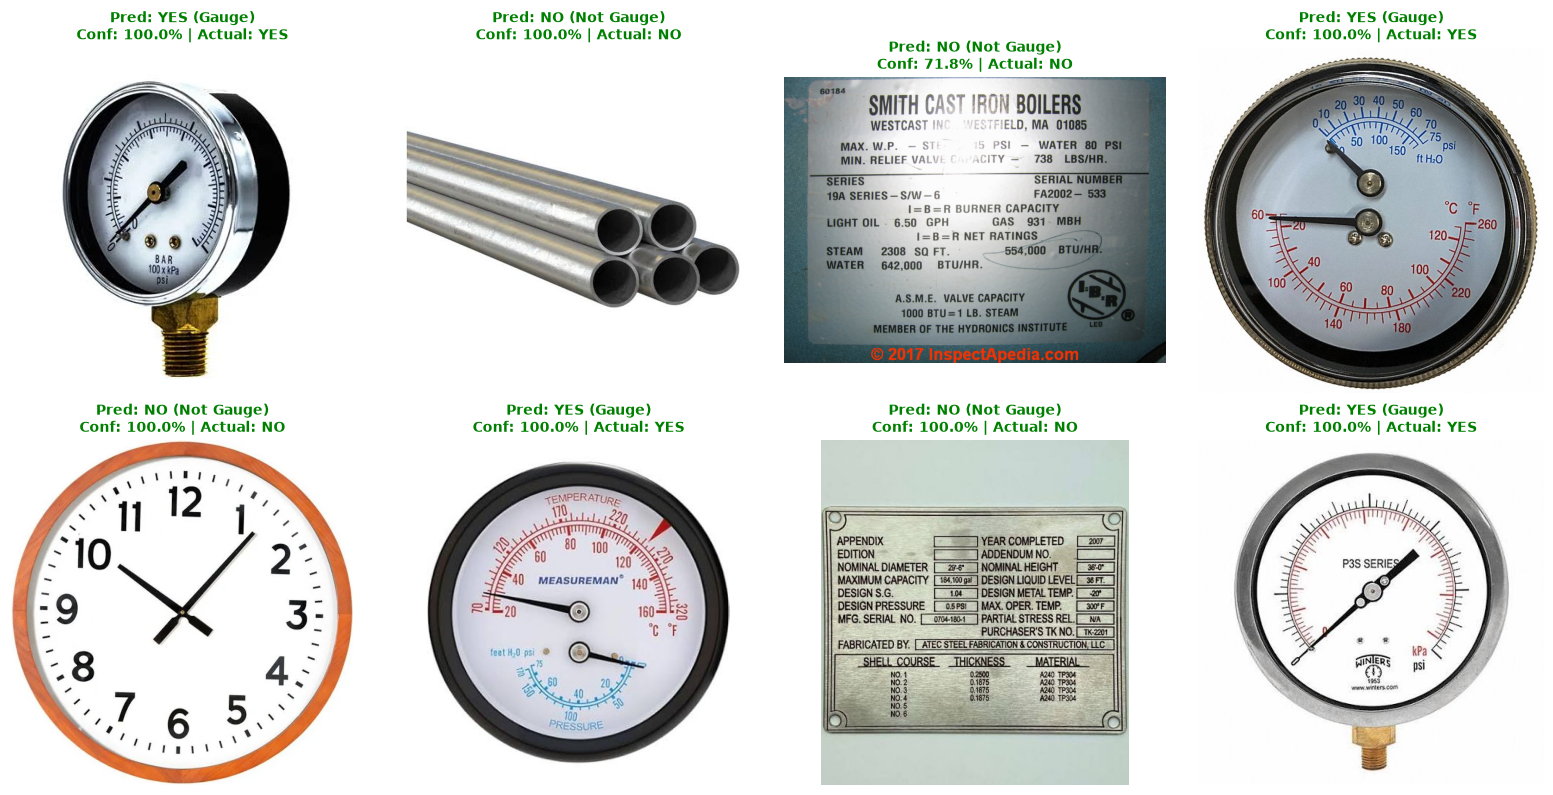

In [16]:
# Cell 5: Visually inspect all 8 unseen Test Set predictions
model.eval()
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (img_path, true_label) in enumerate(zip(X_test, y_test)):
    img = Image.open(img_path).convert("RGB")
    tensor = eval_tfms(img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        prob = torch.sigmoid(model(tensor)).item()
        
    pred_label = 1 if prob >= 0.5 else 0
    conf = prob if pred_label == 1 else (1.0 - prob)
    
    pred_str = "YES (Gauge)" if pred_label == 1 else "NO (Not Gauge)"
    true_str = "YES" if true_label == 1 else "NO"
    is_correct = (pred_label == true_label)
    
    axes[i].imshow(img)
    axes[i].axis("off")
    axes[i].set_title(
        f"Pred: {pred_str}\nConf: {conf:.1%} | Actual: {true_str}",
        color="green" if is_correct else "red",
        fontweight="bold",
        fontsize=10
    )

plt.tight_layout()
plt.show()